# 00 — Your local lab and the post-training map

**Interview priority: essential.** Start here. Prerequisites: Python lists, functions,
and the idea that a model has adjustable numbers called parameters. We introduce
the probability and memory arithmetic we use below. No checkpoint or dataset is downloaded.

**Learning path:** intuition → map → one worked update → resource experiment →
interpretation → interview explanation. Study one section, predict its output,
run it, then explain it aloud. `Run All` is complete; exercises are optional additions.

**Purpose.** Choose a training route from the problem and available evidence.
The inputs to this lesson are synthetic numbers and your local environment; the
outputs are a verified tiny update, a branching map, and an explicit resource budget.
Two demonstration logits and a tiny linear layer train. No pretrained weights are loaded.
Later lessons teach the full algorithms; their presence in this map does not mean
this repository already implements them. See [AUDIT.md](AUDIT.md) and [COURSE.md](COURSE.md).

## 1. First short section: what changes when a model learns?

Think of a model as a function with parameters $\theta$. Given a prompt $x$, it
assigns probabilities to responses $y$: $\pi_\theta(y\mid x)$. Training changes
$\theta$ using evidence. Inference uses the resulting parameters to produce an
output. A retrieval system can supply new evidence in the prompt without changing
model parameters.

**Predict before continuing:** You need answers grounded in a price list updated
every morning. Would you first change model parameters, or retrieve the current
price list? What additional evidence would justify training?

A useful first answer is retrieval with source and freshness checks. SFT could
later teach a stable output format or tool-use behavior. These can be combined.
Neither approach guarantees factual answers; evaluate the whole system.

## 2. A small, separate environment

From the repository root, follow [README.md](README.md). Use the teaching `.venv`
and the **PostTrainingLab Mac** kernel, not the historical server environment.
The supplied lock records the exact resolved teaching packages. Installation needs
internet access; the default lessons do not need it afterwards.

CPU is the default. To try MPS, set `PTL_DEVICE=mps` **before starting the kernel**
or change `DEVICE_NAME` below and restart/run all. An unavailable or unsupported
MPS operation should fail visibly; return to CPU to study the lesson. No silent
backend fallback is enabled. Float64 numerical checks in lesson 01 stay on CPU.

In [1]:
import os
import platform
import sys
import time
from pathlib import Path

os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

START = time.perf_counter()
QUICK_MODE = os.environ.get("PTL_QUICK_MODE", "1") != "0"
DEVICE_NAME = os.environ.get("PTL_DEVICE", "cpu")
assert DEVICE_NAME in {"cpu", "mps"}, "This teaching track accepts cpu or mps."
if DEVICE_NAME == "mps":
    assert torch.backends.mps.is_available(), "MPS unavailable; use PTL_DEVICE=cpu."
DEVICE = torch.device(DEVICE_NAME)
DTYPE = torch.float32
SEED = 17
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
if DEVICE_NAME == "mps":
    torch.mps.manual_seed(SEED)

print({"python": sys.version.split()[0], "torch": torch.__version__,
       "system": platform.system(), "machine": platform.machine(),
       "macOS": platform.mac_ver()[0], "device": str(DEVICE),
       "dtype": str(DTYPE), "quick_mode": QUICK_MODE,
       "mps_built": torch.backends.mps.is_built(),
       "mps_available": torch.backends.mps.is_available()})

{'python': '3.12.15', 'torch': '2.15.0', 'system': 'Darwin', 'machine': 'arm64', 'macOS': '27.0.1', 'device': 'cpu', 'dtype': 'torch.float32', 'quick_mode': True, 'mps_built': True, 'mps_available': True}


`is_available()` is a capability check, not evidence that an entire notebook ran.
[VERIFICATION.md](VERIFICATION.md) records fresh-kernel runs, exact package versions,
wall time, and what was actually checked. Runtime printed by this cell sequence
excludes initial imports; the external runner measures full kernel execution.
Seeds support comparisons; they do not guarantee bitwise equality across devices,
versions, or kernels. Recording the data and configuration matters too.

## 3. A branching landscape, not a mandatory staircase

Read an arrow as **a possible route**. A pretrained checkpoint is normally the
starting asset for adaptation. We create tiny random models locally to learn the
mechanics; that is not a simulation of the knowledge in a large pretrained model.

SFT is often a useful starting policy for preference optimization or RL, but none
of the arrows below requires passing through every other branch. Reward models
feed the PPO branch; DPO directly uses preference pairs. GRPO and PPO are
optimizers. RLVR names a setup where task outcomes can be checked by a verifier.

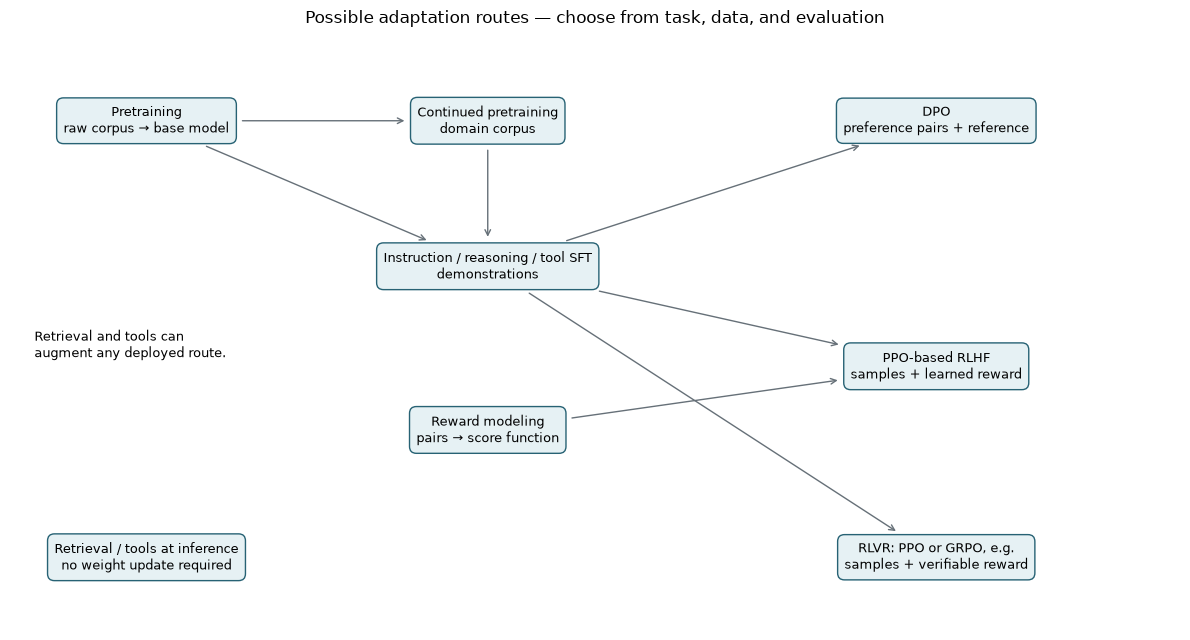

In [2]:
fig, ax = plt.subplots(figsize=(12, 6.5))
ax.set(xlim=(0, 12), ylim=(-0.1, 6.3))
ax.axis("off")
nodes = {
    "base": (1.4, 5.5, "Pretraining\nraw corpus → base model"),
    "cpt": (4.9, 5.5, "Continued pretraining\ndomain corpus"),
    "sft": (4.9, 3.9, "Instruction / reasoning / tool SFT\ndemonstrations"),
    "dpo": (9.5, 5.5, "DPO\npreference pairs + reference"),
    "rm": (4.9, 2.1, "Reward modeling\npairs → score function"),
    "ppo": (9.5, 2.8, "PPO-based RLHF\nsamples + learned reward"),
    "grpo": (9.5, 0.7, "RLVR: PPO or GRPO, e.g.\nsamples + verifiable reward"),
    "rag": (1.4, 0.7, "Retrieval / tools at inference\nno weight update required"),
}
node_labels = {}
for key, (x, y, label) in nodes.items():
    node_labels[key] = ax.text(x, y, label, ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.55", facecolor="#e6f1f4",
                      edgecolor="#276274"))
for a, b in [("base", "cpt"), ("base", "sft"), ("cpt", "sft"),
             ("sft", "dpo"), ("sft", "ppo"), ("rm", "ppo"), ("sft", "grpo")]:
    x1, y1, _ = nodes[a]
    x2, y2, _ = nodes[b]
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", color="#667078", shrinkA=4, shrinkB=4,
                                patchA=node_labels[a].get_bbox_patch(),
                                patchB=node_labels[b].get_bbox_patch()))
ax.text(0.25, 2.9, "Retrieval and tools can\naugment any deployed route.", fontsize=9)
ax.set_title("Possible adaptation routes — choose from task, data, and evaluation", pad=18)
plt.tight_layout()
plt.show()
plt.close(fig)

### Inputs, outputs, and trainable components

| Route | Evidence / input | Trained vs fixed | Intended output / when useful |
|---|---|---|---|
| Pretraining | Broad unlabeled corpus | LM weights trained | General next-token model; expensive starting investment |
| Continued pretraining | Domain text or serialized structured records | LM weights or adapters trained | Adapt domain distribution; does not itself specify an assistant interface |
| Instruction SFT | Prompt + desired answer | Policy weights or adapters trained; targets fixed | Task behavior, format, domain answers supported by examples |
| Reasoning SFT | Problems + answer/trace demonstrations | Policy trained; demonstrations fixed | Learn patterns in supplied solutions; a fluent trace does not prove faithful reasoning |
| Tool-use SFT | Tool schemas and successful trajectories | Policy trained; tools controlled | Calls and response handling; syntax alone is not task success |
| Reward modeling | Prompt, chosen/rejected answer | Reward network/head trained | A preference score, not automatically calibrated utility |
| DPO | Offline chosen/rejected pairs | Policy trained, reference usually frozen | Preference adaptation without a separate learned reward model |
| PPO-based RLHF | Sampled responses + learned reward | Policy and usually value model trained; old rollout policy and reference fixed during updates; reward usually frozen | Optimize a learned reward with sampling and regularization |
| RLVR with GRPO | Same-prompt completion groups + verifier scores | Policy trained; old rollout probabilities fixed; reference if used frozen; no critic in original GRPO | Relative reward optimization on checkable tasks |
| RAG / inference tools | Current documents / database / tool results | Usually no LM weight update in this route | Fresh evidence, provenance, exact external operations |

In PPO the **old** policy supplies the denominator of an importance ratio. The
**reference** anchors regularization. They serve different roles, even if initialized
from the same checkpoint. GRPO also has variants; lesson 09 will name the one it
implements. A verifier is a reward source and can also be used with PPO. A learned
reward is another source. Choice of optimizer does not determine reward validity.

Full fine-tuning, LoRA, and QLoRA describe how parameters are represented or updated,
not a new category of supervision. DPO and SFT can both use LoRA.
Original QLoRA includes NF4, double quantization, and paged optimizers; rounding
a small matrix is only an illustration of quantization. Apple-specific quantized
training extensions remain disabled until the exact backend/version/model is checked.
See the primary [LoRA](https://arxiv.org/abs/2106.09685) and
[QLoRA](https://arxiv.org/abs/2305.14314) papers.

## 4. The mathematics that connects the routes

A model defines $\pi_\theta(y\mid x)$. Here $x$ is a prompt, $y$ is a response,
and $\theta$ is the set of trainable parameters.

**Supervised likelihood:** for a dataset of $N$ demonstrations $(x_i,y_i)$,
$$L_{\mathrm{SFT}}(\theta)=-\frac1N\sum_{i=1}^N\log\pi_\theta(y_i\mid x_i).$$
This expression averages sequence-sum losses over responses. Token-mean reduction
replaces the denominator $N$ with the total supervised-token count; variable lengths change
the effective weighting. Lesson 02 makes those choices explicit. Data and target
token IDs are fixed; the log-probability depends on $\theta$. In a language model,
each sequence log-probability is a sum over its response token log-probabilities.

**Reward optimization, at a high level:**
$$J(\theta)=\mathbb E_{x\sim D,\,y\sim\pi_\theta(\cdot\mid x)}
[r(x,y)]-\beta\,\mathbb E_{x\sim D}
[D_{\mathrm{KL}}(\pi_\theta(\cdot\mid x)\Vert\pi_{\mathrm{ref}}(\cdot\mid x))].$$
$D$ is the prompt distribution, $r$ a reward score, $\beta>0$ a penalty coefficient,
and $\pi_{\mathrm{ref}}$ a fixed reference distribution. For discrete responses,
$D_{\mathrm{KL}}(p\Vert q)=\sum_y p(y)\log[p(y)/q(y)]$, assuming $q>0$ wherever
$p>0$. The outer average is over prompts; the reward average is also over sampled
responses. The reward function may be frozen, while the distribution of sampled
responses depends on $\theta$. Sampling discrete tokens does not provide an ordinary
pathwise gradient: policy gradients use log-probabilities. PPO approximates a
constrained update; clipping is not a hard KL guarantee. [PPO paper](https://arxiv.org/abs/1707.06347).

DPO derives a direct preference-pair loss using a KL-regularized optimal-policy
relationship and a preference model. It does **not** require training a separate
reward network. Beta's theoretical and numerical roles need care; we derive them
in lesson 06. [DPO paper](https://arxiv.org/abs/2305.18290).

## 5. Worked example: two possible answers, one supervised update

This is a categorical model for one fixed prompt, not an implemented RLHF loop.
Let the logit vector $z=(0,0)$, with probabilities
$p_j=\exp(z_j-\max z)/\sum_k\exp(z_k-\max z)$. The demonstrated answer is index 0.
Its loss is $L=-\log p_0$ and $\partial L/\partial z_j=p_j-1[j=0]$.
Shapes: logits `[2]`, target scalar, scalar loss, gradient `[2]`.

**Predict:** Starting at equal probability, which logit increases under gradient
descent $z\leftarrow z-\eta\nabla_zL$? With $\eta=0.2$, calculate the new logits.
There is no padding, masking, token shifting, or sequence-length reduction in this
example. Lesson 01 introduces these additional dimensions.

In [3]:
z = torch.nn.Parameter(torch.zeros(2, device=DEVICE, dtype=DTYPE))
target = torch.tensor(0, device=DEVICE)
optimizer = torch.optim.SGD([z], lr=0.2)
optimizer.zero_grad(set_to_none=True)
loss = F.cross_entropy(z.unsqueeze(0), target.unsqueeze(0))
loss.backward()
assert torch.allclose(z.grad.cpu(), torch.tensor([-0.5, 0.5]))
print("before probabilities:", z.detach().softmax(-1).cpu().tolist())
print("loss:", loss.item(), "gradient:", z.grad.detach().cpu().tolist())
optimizer.step()
with torch.inference_mode():
    after_probability = z.softmax(-1).cpu()
print("updated logits:", z.detach().cpu().tolist())
print("after probabilities:", after_probability.tolist())
assert torch.isfinite(loss) and after_probability[0] > 0.5
optimizer.zero_grad(set_to_none=True)
del optimizer, z, loss

before probabilities: [0.5, 0.5]
loss: 0.6931471824645996 gradient: [-0.5, 0.5]
updated logits: [0.10000000149011612, -0.10000000149011612]
after probabilities: [0.5498339533805847, 0.4501659870147705]


**Interpretation.** The logits become $(0.1,-0.1)$, and the first answer becomes
more probable. Softmax couples all answers through its denominator. This tiny
calculation demonstrates why supervised gradient descent rewards a target; it
does not show that the target is truthful, representative, or useful in deployment.
Choosing reliable supervision and an evaluation scenario is part of the method.

## 6. Memory arithmetic with explicit assumptions

A tensor with dimensions $(d_1,\ldots,d_k)$ and $s$ bytes per element stores
$s\prod_j d_j$ bytes. One GiB is $2^{30}$ bytes; one GB is $10^9$ bytes.

For **this illustrative float32 AdamW implementation**, $P$ trainable parameters
occupy $4P$ bytes, gradients $4P$, and two float32 moment tensors $8P$: $16P$ in
total after optimizer state is initialized. This excludes scalar state, temporaries,
activations, logits, allocator caches, runtime libraries, and Python objects. No
separate master-weight copy is assumed. SGD, frozen parameters, mixed-precision
implementations, sharding, and quantization have different accounts. BF16 compute
does not imply that all parameters or optimizer states are stored in BF16.

Activations depend on the architecture and saved tensors. A materialized single
attention matrix has shape `[B,H,T,T]`; logits have shape `[B,T,V]`. Here $B$ is
batch size, $H$ attention heads, $T$ tokens, and $V$ vocabulary size. Efficient
attention can avoid storing the full matrix. These formulas describe individual
tensors, **not peak training memory**.

In [4]:
GiB = 2**30
P_ILLUSTRATION = 50_000  # A worked illustration, not a measured model in this cell.
for name, size in {"weights": 4 * P_ILLUSTRATION,
                   "gradients": 4 * P_ILLUSTRATION,
                   "two AdamW moments": 8 * P_ILLUSTRATION}.items():
    print(f"{name:22s}: {size:,} bytes")
print(f"illustrative state subtotal: {16 * P_ILLUSTRATION / 2**20:.3f} MiB")
print("engineering target for all default lesson work: comfortably below 6–8 GiB")

weights               : 200,000 bytes
gradients             : 200,000 bytes
two AdamW moments     : 400,000 bytes
illustrative state subtotal: 0.763 MiB
engineering target for all default lesson work: comfortably below 6–8 GiB


On a 16 GiB unified-memory Mac, GPU, CPU, macOS, browser, and notebook workloads
share physical memory. A 6–8 GiB upper engineering target is not a safety guarantee;
these lessons intentionally use far smaller models. Check Activity Monitor for
whole-system memory pressure. Close retained tensors/models or restart the kernel
between experiments. Saving `loss` tensors in a list retains computation graphs;
save `loss.item()` instead. `.eval()` changes layer behavior and does not disable
autograd; use `no_grad()` or `inference_mode()` during inspection and evaluation.

Never increase memory limits just to make an oversized example run. Training a
billion-parameter model is outside the required track. Optional pretrained/MLX
experiments will need model-size, license, memory, and backend verification first.

## 7. Controlled experiment: change only sequence length

**Hypothesis:** Holding $B=2$, $H=2$, vocabulary $V=32$, and float32 fixed,
doubling $T$ quadruples stored attention-matrix bytes and doubles stored logit bytes.
We allocate only these two tensors, record their actual storage payload, and free
them each iteration. All allocations in this accounting experiment stay on CPU
so device and allocator effects do not change with the selected lesson backend.

**Predict:** Does this establish that end-to-end training time must quadruple?

T    attention payload (KiB)   logit payload (KiB)
 16                      4.0                   4.0
 32                     16.0                   8.0
 64                     64.0                  16.0
128                    256.0                  32.0


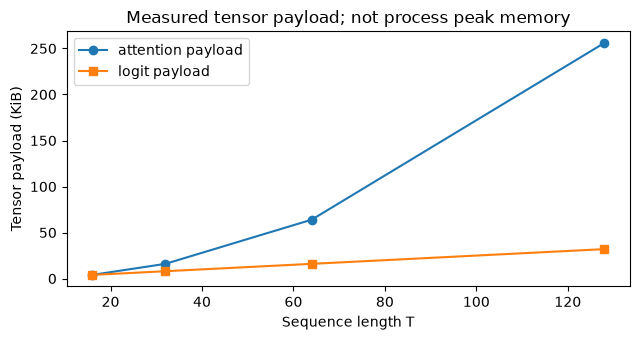

In [5]:
B, H, VOCAB = 2, 2, 32
lengths = [16, 32, 64, 128] if QUICK_MODE else [16, 32, 64, 128, 256]
accounting = []
for T in lengths:
    attention = torch.empty(B, H, T, T, dtype=DTYPE, device="cpu")
    logits = torch.empty(B, T, VOCAB, dtype=DTYPE, device="cpu")
    attention_bytes = attention.numel() * attention.element_size()
    logit_bytes = logits.numel() * logits.element_size()
    assert attention_bytes == 4 * B * H * T**2
    assert logit_bytes == 4 * B * T * VOCAB
    accounting.append((T, attention_bytes, logit_bytes))
    del attention, logits
print("T    attention payload (KiB)   logit payload (KiB)")
for T, a, l in accounting:
    print(f"{T:3d}  {a / 1024:23.1f}   {l / 1024:19.1f}")
for previous, current in zip(accounting, accounting[1:]):
    assert current[1] == 4 * previous[1] and current[2] == 2 * previous[2]
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(lengths, [r[1] / 1024 for r in accounting], "o-", label="attention payload")
ax.plot(lengths, [r[2] / 1024 for r in accounting], "s-", label="logit payload")
ax.set(xlabel="Sequence length T", ylabel="Tensor payload (KiB)",
       title="Measured tensor payload; not process peak memory")
ax.legend()
plt.tight_layout()
plt.show()
plt.close(fig)

**Interpretation.** These deterministic shape counts need no seed confidence
interval. They establish storage scaling for the materialized tensors only.
They do not measure saved autograd intermediates, actual optimizer memory, speed,
peak resident memory, or efficient-attention kernels. Runtime would need warm-up,
device synchronization, repeats, and controlled load; a fanless laptop may throttle.
Lower memory use is useful when quality is preserved, but is not itself evidence
of better predictions or business value.

## 8. Backend check: an actual forward, backward, and update

We compare one deterministic tiny update on the selected device with CPU. The
same initial weights and data are used. Tolerances allow small floating-point
differences. Passing this check validates these operations, not every MPS kernel.
The complete lesson 01 is also executed separately for the verification record.

In [6]:
def one_update(device_name):
    layer = torch.nn.Linear(2, 2, bias=False, device=device_name, dtype=DTYPE)
    with torch.no_grad():
        layer.weight.copy_(torch.tensor([[0.1, -0.2], [0.3, 0.2]], device=device_name))
    x = torch.tensor([[1.0, 2.0], [-1.0, 1.0]], device=device_name)
    y = torch.tensor([0, 1], device=device_name)
    opt = torch.optim.AdamW(layer.parameters(), lr=0.01, weight_decay=0.01, foreach=False)
    opt.zero_grad(set_to_none=True)
    objective = F.cross_entropy(layer(x), y)
    objective.backward()
    assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in layer.parameters())
    opt.step()
    result = (objective.detach().cpu(), layer.weight.detach().cpu().clone())
    opt.zero_grad(set_to_none=True)
    return result

cpu_check = one_update("cpu")
selected_check = one_update(DEVICE_NAME)
assert torch.allclose(cpu_check[0], selected_check[0], atol=1e-5, rtol=1e-4)
assert torch.allclose(cpu_check[1], selected_check[1], atol=1e-5, rtol=1e-4)
if DEVICE_NAME == "mps":
    torch.mps.synchronize()
    print("MPS forward/backward/AdamW parity check passed.")
    print("MPS current allocated bytes:", torch.mps.current_allocated_memory())
else:
    print("CPU forward/backward/AdamW check passed. This run did not execute MPS.")
print(f"lesson cell runtime after imports: {time.perf_counter() - START:.2f} seconds")

CPU forward/backward/AdamW check passed. This run did not execute MPS.
lesson cell runtime after imports: 0.75 seconds


## 9. Connect this map to the actual repository

| Concept here | Existing file / function | Evidence boundary |
|---|---|---|
| Hardware / versions | [`src/utils/env.py`](../../src/utils/env.py), `collect_env`; [`scripts/env_report.py`](../../scripts/env_report.py) | CUDA-focused report; this lesson supplies local MPS checks |
| Memory arithmetic | [`src/utils/memory.py`](../../src/utils/memory.py), `ModelShape.n_params`, `estimate` | Architecture/precision assumptions; output is an estimate |
| Seeding | [`src/utils/seed.py`](../../src/utils/seed.py), `set_seed` | Seeds help; runtime assignment of PYTHONHASHSEED cannot reseed an already started interpreter |
| Base LM exploration | [`scripts/explore_base_model.py`](../../scripts/explore_base_model.py), `inspect_forward`, `inspect_loss` | Historical M1 pretrained-model observations; not our offline path |
| Data and manual SFT | [`notebooks/m2_data_pipeline.py`](../m2_data_pipeline.py), [`tests/test_sft_masking.py`](../../tests/test_sft_masking.py) | M2 materials exist; `src/data/sft.py` and M3 trainer absent at audited commit |
| Preference / RL | [`src/training/dpo/__init__.py`](../../src/training/dpo/__init__.py), [`src/training/ppo/__init__.py`](../../src/training/ppo/__init__.py), [`src/training/grpo/__init__.py`](../../src/training/grpo/__init__.py) | Empty placeholders, not completed training stages |

The older README's linear track is a learning outline, not a universal training
requirement. Historical OLMo EOS behavior came from particular models, prompts,
tokenizers, and decoding choices. No one example proves what all base models do.
A production system adds representative data, entity/time-safe evaluation, richer
capacity, monitoring, access controls, deployment checks, and cost accounting.

## 10. Practice — try before opening the solutions

1. **Easy:** Does retrieving a document necessarily change model parameters?
2. **Calculate / modify:** If $T$ doubles and $V$ doubles, what happens to the
   payload of `[B,T,V]` float32 logits? Change `VOCAB` and verify the arithmetic.
3. **Why / debug:** Preference pairs exist but no reliable numeric reward model.
   Must you first train a reward network and run PPO? What evaluation would you
   require before calling preference optimization successful?

**Interview explanation (adapt to what you have actually studied):**
“I choose adaptation from the failure mode and evidence. Continued pretraining
adapts a text distribution; SFT learns demonstrated responses; preference methods
use comparisons or rewards. DPO can use offline pairs directly, while PPO-based
RLHF samples responses scored by a learned reward. Verifiable rewards are a reward
setup that can be paired with optimizers such as PPO or GRPO. Retrieval provides
current evidence at inference. In my Mac learning track I have executed tiny
probability and gradient mechanics; the repository's larger RL stages remain planned.”

Likely follow-ups and strong-answer points:
- **Why not fine-tune for every fresh fact?** Freshness, provenance, update cost,
  uncertain memorization, and an end-to-end retrieval baseline.
- **Why not optimize any reward until it is high?** Proxy errors, reward hacking,
  held-out task success, segment analysis, and human/business constraints.
- **How do LoRA and SFT relate?** Parameterization/update scope versus supervision;
  retain frozen-weight and activation costs when accounting for memory.
- **What would you claim in an interview today?** Separate historical recorded
  runs, newly executed toy work, material studied, and unimplemented plans.

### Worked solutions — pause here if you want to try first

1. No. Retrieval normally changes the context supplied to the model. A separate
   training process would be needed to change its parameters.
2. Four times the logit payload: $4\,B(2T)(2V)=4\times[4BTV]$ bytes. This says
   nothing by itself about peak memory or runtime.
3. No. Standard DPO uses pairs plus a reference policy without a separately
   trained reward network. Keep a held-out preference set, test actual task
   quality/retention and relevant segments, and inspect label quality and shift.
   A better preference objective value alone does not establish business impact.

**Next:** open lesson 01. Keep the distinction between fixed evidence, trainable
parameters, and sampled outputs in mind. Record your explanations in
[PROGRESS.md](PROGRESS.md); successful execution is not evidence of mastery.

## References

Primary theory: [InstructGPT / RLHF](https://arxiv.org/abs/2203.02155),
[DPO](https://arxiv.org/abs/2305.18290), [PPO](https://arxiv.org/abs/1707.06347),
[DeepSeekMath / original GRPO](https://arxiv.org/abs/2402.03300),
[LoRA](https://arxiv.org/abs/2106.09685), [QLoRA](https://arxiv.org/abs/2305.14314),
[domain-adaptive pretraining](https://aclanthology.org/2020.acl-main.740/),
[RAG](https://arxiv.org/abs/2005.11401).

Official APIs: [MPS backend](https://docs.pytorch.org/docs/stable/notes/mps.html),
[MPS synchronization and memory](https://docs.pytorch.org/docs/stable/mps.html),
[AdamW](https://docs.pytorch.org/docs/stable/generated/torch.optim.AdamW.html),
[reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html),
[evaluation versus gradient modes](https://docs.pytorch.org/docs/stable/notes/autograd.html#locally-disabling-gradient-computation).
Stable URLs may advance; [VERIFICATION.md](VERIFICATION.md) records the actual
installed version and APIs exercised. Further algorithm derivations belong to
their corresponding lessons, not to this setup demonstration.